# 01 — Exploratory Data Analysis (EDA)

**Project:** diabetes prediction with supervised classification.
**Dataset:** `data/raw/diabetes_pt.csv` (Portuguese translation of the Pima Indians Diabetes dataset).

Goals of this notebook:

1. Understand the structure, types and statistics of the data.
2. Find missing, invalid or problematic values. In particular, find out whether some **zeros are really missing measurements**.
3. Study distributions, outliers, correlations, and how each predictor relates to the target `Resultado`.
4. Turn these findings into **justified preprocessing decisions** (summary table in §10).

> **Methodological note.** Sections 1–8 are *descriptive* and use the full dataset. That is standard practice, because they only describe the data and do not fit anything. In §9 we compare preprocessing strategies by actually training models, so that section uses **only the training split** (with cross-validation). The test set stays untouched until the final evaluation in Phase 3.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import ListedColormap
from scipy import stats

from diabetes.config import FEATURES, RANDOM_SEED, TABLES_DIR, TARGET, TEST_SIZE, ZERO_AS_MISSING
from diabetes.data import load_raw, zeros_to_nan
from diabetes.plotting import CLASS_COLORS, CLASS_LABELS, DIVERGING_CMAP, NEUTRAL, apply_style, save_fig

apply_style()
pd.set_option("display.precision", 3)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

df = load_raw()

## 1. Dataset structure

In [2]:
structure = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "n_null": df.isna().sum(),
})
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns | duplicated rows: {df.duplicated().sum()}")
display(df.head())
structure

Shape: 768 rows x 9 columns | duplicated rows: 0


,Gavidez,Glicose,PressaoArterial,Espesura_da_Pele,Insulina,IMC,Diabetes_Hereditaria,Idade,Resultado
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


,dtype,n_unique,n_null
Gavidez,int64,17,0
Glicose,int64,136,0
PressaoArterial,int64,47,0
Espesura_da_Pele,int64,51,0
Insulina,int64,186,0
IMC,float64,248,0
Diabetes_Hereditaria,float64,517,0
Idade,int64,52,0
Resultado,int64,2,0


**Findings**

- 768 rows and 9 columns: 8 predictors plus the target `Resultado`. This matches the assignment.
- Every column is numeric (`int64` or `float64`). There are **no categorical predictors**, so no encoding (one-hot etc.) is needed.
- There are **no `NaN` values** and **no duplicated rows**. As §4 shows, "no NaN" does *not* mean "no missing data".
- `Resultado` is stored as an integer 0/1 but is a **class label**, not a quantity. That matters in Orange: unless the column is declared *categorical* in the File widget, Orange treats the problem as regression.

## 2. Descriptive statistics

In [3]:
desc = df.describe().T
desc["n_zeros"] = (df == 0).sum()
desc["skew"] = df.skew()
desc.to_csv(TABLES_DIR / "descriptive_stats_raw.csv")
desc

,count,mean,std,min,25%,50%,75%,max,n_zeros,skew
Gavidez,768.0,3.845,3.370,0.000,1.000,3.000,6.000,17.00,111,0.902
Glicose,768.0,120.895,31.973,0.000,99.000,117.000,140.250,199.00,5,0.174
PressaoArterial,768.0,69.105,19.356,0.000,62.000,72.000,80.000,122.00,35,-1.844
Espesura_da_Pele,768.0,20.536,15.952,0.000,0.000,23.000,32.000,99.00,227,0.109
Insulina,768.0,79.799,115.244,0.000,0.000,30.500,127.250,846.00,374,2.272
IMC,768.0,31.993,7.884,0.000,27.300,32.000,36.600,67.10,11,-0.429
Diabetes_Hereditaria,768.0,0.472,0.331,0.078,0.244,0.372,0.626,2.42,0,1.920
Idade,768.0,33.241,11.760,21.000,24.000,29.000,41.000,81.00,0,1.130
Resultado,768.0,0.349,0.477,0.000,0.000,0.000,1.000,1.00,500,0.635


**Findings**

- `Glicose`, `PressaoArterial`, `Espesura_da_Pele`, `Insulina` and `IMC` all have **minimum 0**. A living person cannot have glucose, diastolic pressure, skinfold thickness or BMI equal to zero. These zeros are examined in §4.
- `Insulina` has its **25th percentile at 0**, so at least a quarter of its values are zero. `Espesura_da_Pele` behaves the same way.
- `Insulina` has a very large spread (std 115, max 846) and strong right skew. `Diabetes_Hereditaria` is also right-skewed.
- `Idade` ranges from 21 to 81. The original study included only women aged 21 or older, which limits how far the results generalize.
- `Gavidez` reaches 17. That is unusual but possible: the 17-pregnancy record belongs to a 47-year-old.

## 3. Target distribution and class imbalance

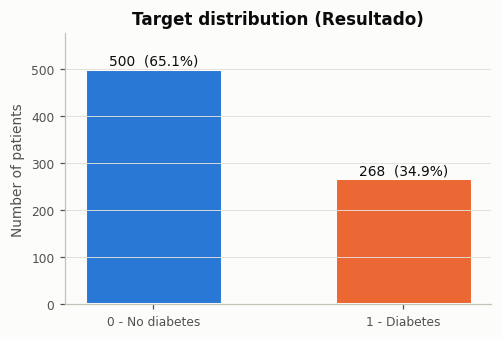

Imbalance ratio (0:1) = 1.87 : 1
Majority-class baseline accuracy = 0.651


In [4]:
counts = df[TARGET].value_counts().sort_index()
share = counts / counts.sum()

fig, ax = plt.subplots(figsize=(5, 3.2))
bars = ax.bar([CLASS_LABELS[c] for c in counts.index], counts.values,
              color=[CLASS_COLORS[c] for c in counts.index], width=0.55, edgecolor="#fcfcfb", linewidth=2)
for bar, n, p in zip(bars, counts.values, share.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n + 8, f"{n}  ({p:.1%})", ha="center", fontsize=9, color="#0b0b0b")
ax.set_ylabel("Number of patients")
ax.set_title("Target distribution (Resultado)")
ax.set_ylim(0, counts.max() * 1.15)
ax.grid(axis="x", visible=False)
save_fig(fig, "01_target_distribution")
plt.show()

print(f"Imbalance ratio (0:1) = {counts[0] / counts[1]:.2f} : 1")
print(f"Majority-class baseline accuracy = {share.max():.3f}")

**Concept: why imbalance matters.** A trivial "model" that always predicts *no diabetes* already scores **65.1% accuracy**, yet its **recall is 0**, because it never detects a single diabetic patient. So:

- Accuracy alone is misleading here. Any real model must clearly beat **0.651**, and it must be judged on **recall, precision and F1** for class 1.
- The imbalance is **moderate** (1.87 : 1), not extreme. Resampling techniques such as SMOTE are not required. **Stratified splitting** (and stratified CV) is enough to keep about 35% positives in every subset.

## 4. Zero values: legitimate observations or missing measurements?

**Concept: missing-data mechanisms.** Statistics distinguishes three cases:

- **MCAR** (missing completely at random): whether a value is missing has nothing to do with any variable.
- **MAR** (missing at random): missingness depends on *other observed* variables.
- **MNAR** (missing not at random): missingness depends on the missing value itself.

The mechanism matters. Under MCAR, simple imputation is fairly harmless. If missingness is related to the target, the fact that a value is missing can itself carry predictive information.

First, is a zero **physiologically possible** in each column?

| Column | Is 0 plausible? | Reasoning |
|---|---|---|
| `Gavidez` | **Yes** | Zero pregnancies is common. |
| `Glicose` | No | Plasma glucose of 0 is incompatible with life. |
| `PressaoArterial` | No | Diastolic pressure of 0 is impossible in a living patient. |
| `Espesura_da_Pele` | No | A skinfold always has some thickness. |
| `Insulina` | No | 2-h serum insulin after a glucose load is never exactly 0. |
| `IMC` | No | BMI = weight / height²; it is 0 only if weight is 0. |
| `Diabetes_Hereditaria` | — | No zeros present (min 0.078). |
| `Idade` | — | No zeros present (min 21). |

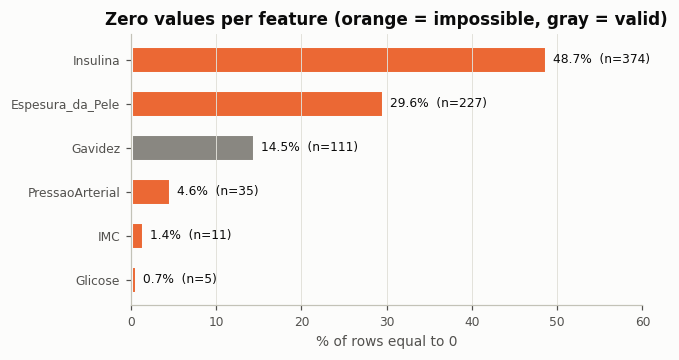

,n_zeros,pct_zeros,zero_is_missing
Insulina,374,48.698,True
Espesura_da_Pele,227,29.557,True
Gavidez,111,14.453,False
PressaoArterial,35,4.557,True
IMC,11,1.432,True
Glicose,5,0.651,True
Diabetes_Hereditaria,0,0.000,False
Idade,0,0.000,False


In [5]:
zero_table = pd.DataFrame({
    "n_zeros": (df[FEATURES] == 0).sum(),
    "pct_zeros": (df[FEATURES] == 0).mean() * 100,
    "zero_is_missing": [c in ZERO_AS_MISSING for c in FEATURES],
}).sort_values("n_zeros", ascending=False)
zero_table.to_csv(TABLES_DIR / "zero_counts.csv")

plot_df = zero_table[zero_table["n_zeros"] > 0].iloc[::-1]
fig, ax = plt.subplots(figsize=(6, 3.2))
colors = ["#eb6834" if m else NEUTRAL for m in plot_df["zero_is_missing"]]
ax.barh(plot_df.index, plot_df["pct_zeros"], color=colors, height=0.6, edgecolor="#fcfcfb", linewidth=2)
for y, (pct, n) in enumerate(zip(plot_df["pct_zeros"], plot_df["n_zeros"])):
    ax.text(pct + 0.8, y, f"{pct:.1f}%  (n={n})", va="center", fontsize=8, color="#0b0b0b")
ax.set_xlabel("% of rows equal to 0")
ax.set_title("Zero values per feature (orange = impossible, gray = valid)")
ax.set_xlim(0, 60)
ax.grid(axis="y", visible=False)
save_fig(fig, "02_zeros_by_feature")
plt.show()
zero_table

**How are the zeros distributed across rows?** If the missing values cluster in the same patients, that says something about *why* they are missing.

Rows by number of missing fields:
0    392
1    142
2    199
3     28
4      7

Rows with at least one missing value: 376 of 768 (49.0%)

Co-occurrence of missing Espesura_da_Pele and Insulina:


Insulina missing,False,True
Pele missing,,
False,394,147
True,0,227


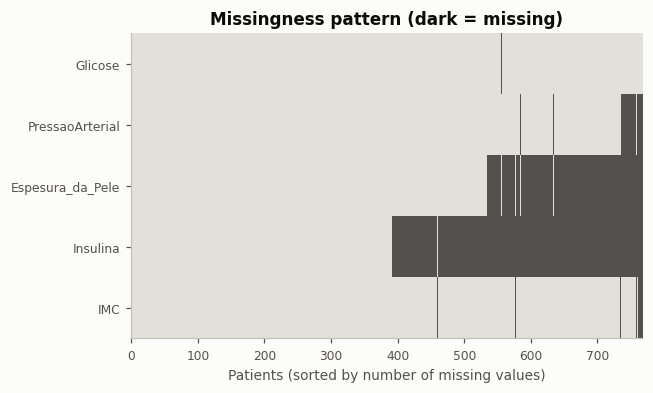

In [6]:
df_nan = zeros_to_nan(df)                     # impossible zeros -> NaN (stateless step)
miss = df_nan[ZERO_AS_MISSING].isna()

n_missing_per_row = miss.sum(axis=1)
print("Rows by number of missing fields:")
print(n_missing_per_row.value_counts().sort_index().to_string())
print(f"\nRows with at least one missing value: {miss.any(axis=1).sum()} of {len(df)} ({miss.any(axis=1).mean():.1%})")
print("\nCo-occurrence of missing Espesura_da_Pele and Insulina:")
display(pd.crosstab(miss["Espesura_da_Pele"], miss["Insulina"],
                    rownames=["Pele missing"], colnames=["Insulina missing"]))

# Missingness matrix: one row per patient, sorted by how many values are missing.
order = n_missing_per_row.sort_values(kind="stable").index
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.imshow(miss.loc[order].T.values, aspect="auto", interpolation="nearest",
          cmap=ListedColormap(["#e1e0d9", "#52514e"]))
ax.set_yticks(range(len(ZERO_AS_MISSING)), ZERO_AS_MISSING)
ax.set_xlabel("Patients (sorted by number of missing values)")
ax.set_title("Missingness pattern (dark = missing)")
ax.grid(False)
save_fig(fig, "03_missingness_pattern")
plt.show()

**Findings**

- **376 of 768 rows (49%)** have at least one missing value. Deleting every incomplete row (*listwise deletion*) would throw away about half the dataset, which is **not acceptable**.
- **Every one of the 227 rows with missing `Espesura_da_Pele` is also missing `Insulina`.** This structured pattern suggests the two measurements were often skipped together during data collection, for example as part of the same examination step. It is not random noise in individual fields. (This is an inference from the pattern; the dataset documentation does not confirm it.)
- `Glicose` (5) and `IMC` (11) have very few missing values, so how we treat them has little effect.

**Next question: is missingness related to the target?** If, say, diabetics were more often missing insulin, then "missing" would be a signal, and a *missing-indicator* feature could help.

**Concept: chi-square / Fisher test.** Both test whether the positive rate is the same whether a value is missing or present. A small p-value (< 0.05) would suggest an association. Fisher's exact test is used as a check because `Glicose` has only 5 missing values, too few for the chi-square approximation.

In [7]:
rows = []
for col in ZERO_AS_MISSING:
    is_missing = miss[col]
    table = pd.crosstab(is_missing, df[TARGET])
    rows.append({
        "feature": col,
        "n_missing": int(is_missing.sum()),
        "pos_rate_if_missing": df.loc[is_missing, TARGET].mean(),
        "pos_rate_if_present": df.loc[~is_missing, TARGET].mean(),
        "chi2_p": stats.chi2_contingency(table)[1],
        "fisher_p": stats.fisher_exact(table)[1],
    })
missing_vs_target = pd.DataFrame(rows).set_index("feature")
missing_vs_target.to_csv(TABLES_DIR / "missingness_vs_target.csv")
missing_vs_target

,n_missing,pos_rate_if_missing,pos_rate_if_present,chi2_p,fisher_p
feature,,,,,
Glicose,5,0.400,0.349,1.000,1.000
PressaoArterial,35,0.457,0.344,0.233,0.203
Espesura_da_Pele,227,0.388,0.333,0.169,0.159
Insulina,374,0.369,0.330,0.290,0.289
IMC,11,0.182,0.351,0.394,0.346


**Findings**

- For every column, the positive rate is **not significantly different** between rows with and without the value (all p > 0.15). Missing `Insulina` rows are 36.9% positive against 33.0% otherwise, which is well within chance variation.
- So missingness carries **no detectable information about the target**. That fits MCAR with respect to `Resultado`, though it cannot prove it, and it predicts that missing-indicator features **will not help**. §9 tests this prediction.
- **Conclusion:** the zeros in the five columns are **missing values**, and we convert them to `NaN` and impute them. Converting to `NaN` learns nothing from the data, so doing it before the split does not leak information. Imputation *does* learn (for example the median), so it must be fitted on the training data only.

## 5. Distributions of the numerical variables

First the **raw** data, to see how the zeros distort the distributions.

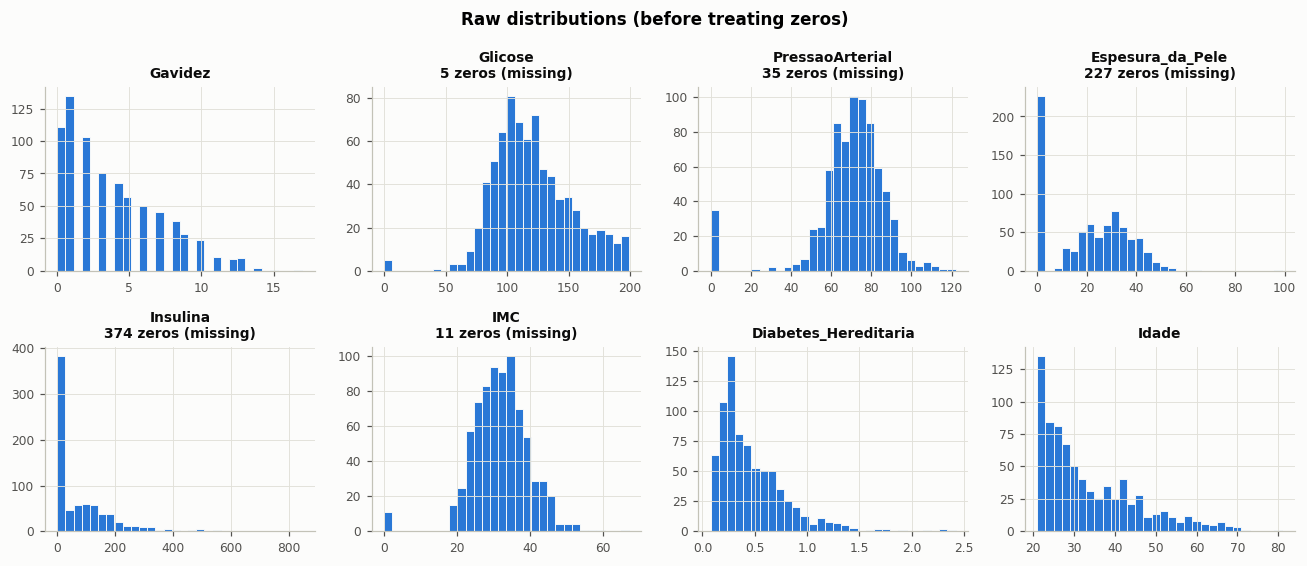

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(12, 5.2))
for ax, col in zip(axes.flat, FEATURES):
    ax.hist(df[col], bins=30, color="#2a78d6", edgecolor="#fcfcfb", linewidth=0.6)
    n0 = (df[col] == 0).sum()
    if col in ZERO_AS_MISSING:
        ax.set_title(f"{col}\n{n0} zeros (missing)", fontsize=9)
    else:
        ax.set_title(col, fontsize=9)
    ax.set_ylabel("")
fig.suptitle("Raw distributions (before treating zeros)", fontsize=11, fontweight="semibold")
fig.tight_layout()
save_fig(fig, "04_hist_raw")
plt.show()

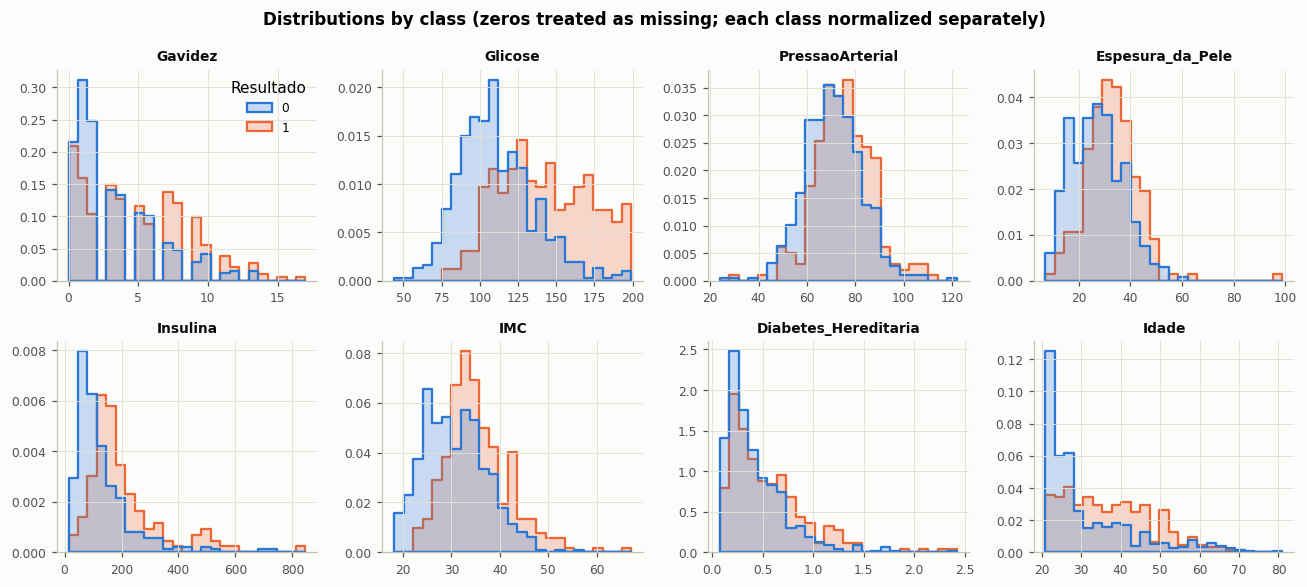

,skew_raw,skew_zeros_as_nan
Gavidez,0.902,0.902
Glicose,0.174,0.531
PressaoArterial,-1.844,0.134
Espesura_da_Pele,0.109,0.691
Insulina,2.272,2.166
IMC,-0.429,0.594
Diabetes_Hereditaria,1.920,1.920
Idade,1.130,1.130


In [9]:
fig, axes = plt.subplots(2, 4, figsize=(12, 5.4))
for ax, col in zip(axes.flat, FEATURES):
    sns.histplot(data=df_nan, x=col, hue=TARGET, palette=CLASS_COLORS, stat="density",
                 common_norm=False, element="step", fill=True, alpha=0.25, linewidth=1.5,
                 bins=25, ax=ax, legend=(col == FEATURES[0]))
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel("")
legend = axes.flat[0].get_legend()
legend.set_title("Resultado")
fig.suptitle("Distributions by class (zeros treated as missing; each class normalized separately)",
             fontsize=11, fontweight="semibold")
fig.tight_layout()
save_fig(fig, "05_hist_by_class")
plt.show()

skew = pd.DataFrame({"skew_raw": df[FEATURES].skew(), "skew_zeros_as_nan": df_nan[FEATURES].skew()})
skew

**Findings**

- The zeros create **artificial spikes** far from the real data. For `PressaoArterial`, the zeros alone produce a strong left skew (**−1.84**). Once they are treated as missing, the distribution is nearly symmetric (**0.13**). The zeros are distortions, not information.
- After cleaning, `Glicose`, `PressaoArterial` and `IMC` are roughly bell-shaped. `Insulina` (2.17), `Diabetes_Hereditaria` (1.92), `Idade` (1.13) and `Gavidez` (0.90) remain **right-skewed**.
- Skewness is one reason to impute with the **median** rather than the mean: the median is not pulled toward the long tail.
- **Class separation:** `Glicose` shows the clearest shift (diabetics have visibly higher glucose). `IMC`, `Idade` and `Insulina` show moderate shifts. In every variable the two classes **overlap substantially**, so no single variable separates them, and we should not expect near-perfect classification.

## 6. Outliers

**Concept: the IQR rule.** A value is flagged as an outlier if it lies below Q1 − 1.5·IQR or above Q3 + 1.5·IQR, where IQR = Q3 − Q1. This is the rule boxplot whiskers use. An outlier is a *statistically unusual* value, **not necessarily an error**. Deciding which it is needs domain knowledge.

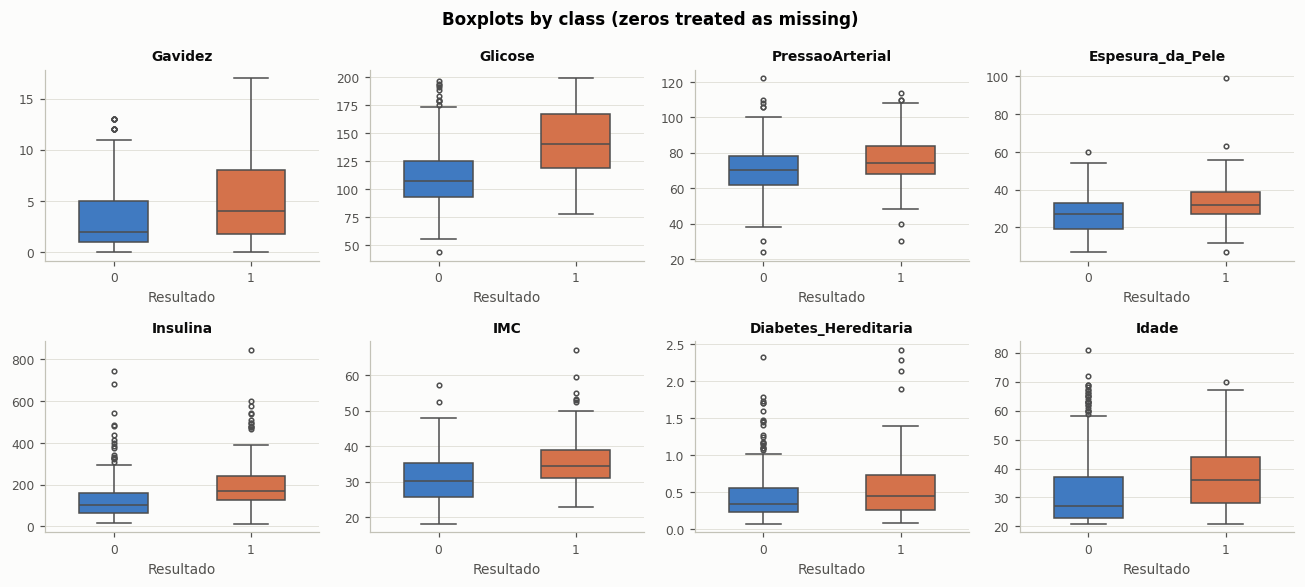

,lower_fence,upper_fence,n_outliers,min,max
feature,,,,,
Diabetes_Hereditaria,-0.330,1.200,29,0.078,2.42
Insulina,-94.375,360.625,24,14.000,846.00
PressaoArterial,40.000,104.000,14,24.000,122.00
Idade,-1.500,66.500,9,21.000,81.00
IMC,13.850,50.250,8,18.200,67.10
Gavidez,-6.500,13.500,4,0.000,17.00
Espesura_da_Pele,1.000,57.000,3,7.000,99.00
Glicose,36.000,204.000,0,44.000,199.00


In [10]:
fig, axes = plt.subplots(2, 4, figsize=(12, 5.4))
for ax, col in zip(axes.flat, FEATURES):
    sns.boxplot(data=df_nan, x=TARGET, y=col, hue=TARGET, palette=CLASS_COLORS, legend=False,
                width=0.5, linewidth=1, fliersize=3, ax=ax)
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("Resultado")
    ax.set_ylabel("")
fig.suptitle("Boxplots by class (zeros treated as missing)", fontsize=11, fontweight="semibold")
fig.tight_layout()
save_fig(fig, "06_boxplots_by_class")
plt.show()

rows = []
for col in FEATURES:
    s = df_nan[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append({"feature": col, "lower_fence": low, "upper_fence": high,
                 "n_outliers": int(((s < low) | (s > high)).sum()), "min": s.min(), "max": s.max()})
outliers = pd.DataFrame(rows).set_index("feature").sort_values("n_outliers", ascending=False)
outliers.to_csv(TABLES_DIR / "outliers_iqr.csv")
outliers

In [11]:
# Inspect the most extreme cases to judge clinical plausibility.
print("Highest Insulina:")
display(df_nan.nlargest(3, "Insulina")[["Insulina", "Glicose", "IMC", "Resultado"]])
print("Highest Espesura_da_Pele (next-highest values for comparison):")
display(df_nan.nlargest(3, "Espesura_da_Pele")[["Espesura_da_Pele", "IMC", "Resultado"]])
print("Lowest PressaoArterial:")
display(df_nan.nsmallest(3, "PressaoArterial")[["PressaoArterial", "Idade", "Resultado"]])

Highest Insulina:


,Insulina,Glicose,IMC,Resultado
13,846.0,189.0,30.1,1
228,744.0,197.0,36.7,0
247,680.0,165.0,52.3,0


Highest Espesura_da_Pele (next-highest values for comparison):


,Espesura_da_Pele,IMC,Resultado
579,99.0,34.7,1
445,63.0,59.4,1
57,60.0,46.8,0


Lowest PressaoArterial:


,PressaoArterial,Idade,Resultado
597,24.0,21,0
18,30.0,33,0
125,30.0,26,1


**Findings**

- The most outliers are in `Diabetes_Hereditaria` (29), `Insulina` (24) and `PressaoArterial` (14). Most of them are simply the long right tails seen in §5.
- **Clinical review of the extremes:**
  - `Insulina` = 846 together with `Glicose` = 189 is a high but **plausible** combination (strong insulin response to high glucose).
  - `Espesura_da_Pele` = 99 mm is **suspicious**, since the next-highest value is 63 mm. It may be a recording error, but it is a single row.
  - `PressaoArterial` = 24 mmHg is **implausibly low** for a 21-year-old, but we cannot verify it.
  - `IMC` = 67.1 indicates severe obesity, which is **plausible**.
- **Decision: keep all outliers.** (1) Most are plausible extreme patients, and removing them would teach the model that such patients don't exist. (2) With 768 rows, every record matters. (3) We have no clinical ground truth to tell errors from real extremes. (4) Random Forest is insensitive to extreme values. Logistic Regression and KNN are somewhat affected, but standardization keeps the influence limited. (5) Removing outliers from the *test* set would make the evaluation unrealistically optimistic.
- *Optional improvement:* a sensitivity analysis (training with and without the few suspicious rows) or a log transform of `Insulina` and `Diabetes_Hereditaria`.

## 7. Correlations

**Concept.** *Pearson* measures **linear** association. *Spearman* is Pearson computed on ranks, so it measures any **monotonic** association and is robust to skew and outliers. We compute both on the cleaned data (zeros as `NaN`, pairwise deletion). With a binary target, Pearson correlation is the *point-biserial* correlation.

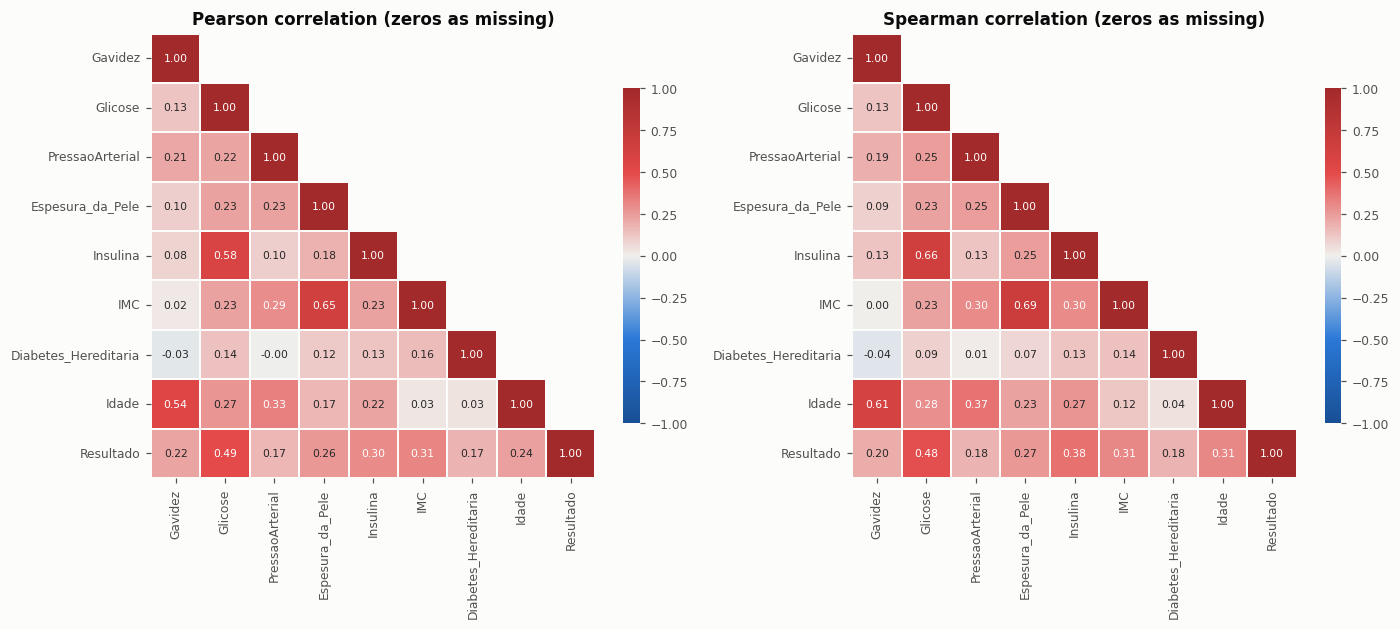

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = df_nan.corr(method=method)
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    sns.heatmap(corr, mask=mask, cmap=DIVERGING_CMAP, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
                annot_kws={"size": 7}, linewidths=1, linecolor="#fcfcfb", square=True,
                cbar_kws={"shrink": 0.7}, ax=ax)
    ax.set_title(f"{method.capitalize()} correlation (zeros as missing)")
    ax.grid(False)
fig.tight_layout()
save_fig(fig, "07_correlation_heatmaps")
plt.show()

In [13]:
# Does treating zeros as missing change how strongly each feature relates to the target?
target_corr = pd.DataFrame({
    "pearson_raw_zeros": df.corr()[TARGET],
    "pearson_zeros_as_nan": df_nan.corr()[TARGET],
    "spearman_zeros_as_nan": df_nan.corr(method="spearman")[TARGET],
}).drop(TARGET).sort_values("pearson_zeros_as_nan", ascending=False)
target_corr.to_csv(TABLES_DIR / "correlation_with_target.csv")
target_corr

,pearson_raw_zeros,pearson_zeros_as_nan,spearman_zeros_as_nan
Glicose,0.467,0.495,0.483
IMC,0.293,0.314,0.309
Insulina,0.131,0.303,0.377
Espesura_da_Pele,0.075,0.259,0.265
Idade,0.238,0.238,0.309
Gavidez,0.222,0.222,0.199
Diabetes_Hereditaria,0.174,0.174,0.175
PressaoArterial,0.065,0.171,0.177


**Findings**

- **Strongest predictor pairs:** `Espesura_da_Pele`–`IMC` (r = 0.65), `Glicose`–`Insulina` (0.58), `Gavidez`–`Idade` (0.54). All are physiologically expected: skinfold reflects body fat, insulin responds to glucose, and older women have had more pregnancies.
- **No pair exceeds 0.8**, so **multicollinearity is not severe**. Strong multicollinearity mostly destabilizes the *interpretation* of Logistic Regression coefficients rather than predictive performance. **All 8 features are kept.**
- **Correlation with the target:** `Glicose` is by far the strongest (0.50), followed by `IMC` (0.31), `Insulina` (0.30), `Espesura_da_Pele` (0.26) and `Idade` (0.24).
- **The zeros hid real signal.** Treating them as missing raises the target correlation of `Espesura_da_Pele` from **0.07 to 0.26**, of `Insulina` from **0.13 to 0.30**, and of `PressaoArterial` from **0.07 to 0.17**. This is strong evidence that the zeros are noise, not real measurements.
- `Insulina` has a much higher Spearman (0.38) than Pearson (0.30) correlation, so its relation to the target is monotonic but not linear, as expected given its skew.

## 8. Relationship between each predictor and the target

**Concept: Mann–Whitney U test.** It tests whether one class tends to have larger values than the other. Unlike the t-test, it does not assume normal distributions, which suits our skewed variables.

In [14]:
rows = []
for col in FEATURES:
    neg = df_nan.loc[df[TARGET] == 0, col].dropna()
    pos = df_nan.loc[df[TARGET] == 1, col].dropna()
    rows.append({"feature": col, "median_class0": neg.median(), "median_class1": pos.median(),
                 "mean_class0": neg.mean(), "mean_class1": pos.mean(),
                 "mannwhitney_p": stats.mannwhitneyu(neg, pos).pvalue})
univariate = pd.DataFrame(rows).set_index("feature").sort_values("mannwhitney_p")
univariate.to_csv(TABLES_DIR / "univariate_tests.csv")
univariate

,median_class0,median_class1,mean_class0,mean_class1,mannwhitney_p
feature,,,,,
Glicose,107.000,140.000,110.644,142.320,1.305e-40
Idade,27.000,36.000,31.190,37.067,1.142e-17
IMC,30.100,34.300,30.860,35.407,1.819e-17
Insulina,102.500,169.500,130.288,206.846,7.477e-14
Espesura_da_Pele,27.000,32.000,27.235,33.000,6.961e-10
Gavidez,2.000,4.000,3.298,4.866,3.745e-08
Diabetes_Hereditaria,0.336,0.449,0.430,0.550,1.197e-06
PressaoArterial,70.000,74.500,70.877,75.321,1.629e-06


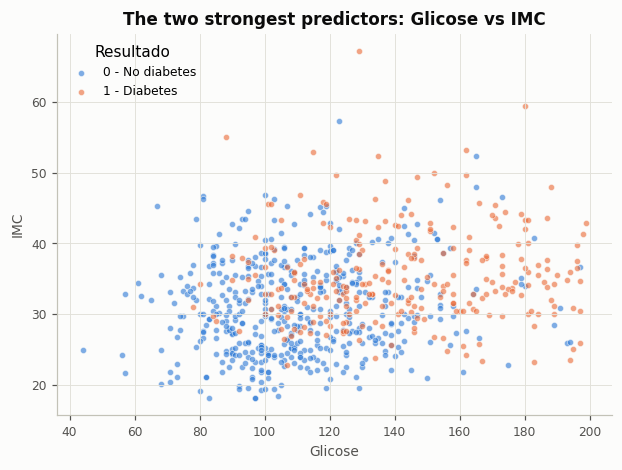

In [15]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for cls in [0, 1]:
    sub = df_nan[df[TARGET] == cls]
    ax.scatter(sub["Glicose"], sub["IMC"], s=16, alpha=0.6, color=CLASS_COLORS[cls],
               edgecolor="#fcfcfb", linewidth=0.5, label=CLASS_LABELS[cls])
ax.set_xlabel("Glicose")
ax.set_ylabel("IMC")
ax.set_title("The two strongest predictors: Glicose vs IMC")
ax.legend(title="Resultado", loc="upper left")
save_fig(fig, "08_scatter_glucose_bmi")
plt.show()

**Findings**

- Every predictor differs **significantly** between classes (all p < 10⁻⁵). Diabetics have higher medians in all eight. The ranking agrees with the correlations: `Glicose` (p ≈ 10⁻⁴⁰) is far ahead, then `IMC` and `Idade`.
- **Caution: statistical significance is not predictive power.** With hundreds of rows, even a small shift becomes "significant". The scatter plot is more honest: patients with high glucose *and* high BMI are mostly diabetic, but the middle region is **heavily mixed**. Every model will make errors there, and the false negatives are what we care about most.

## 9. Testing the preprocessing options (training data only)

§4 left several candidate ways to handle the missing values. Instead of choosing by intuition, we **measure** them.

**Why use only the training data?** If we picked a strategy because it scored best on the *test* set, the test score would no longer be an unbiased estimate of future performance: we would have tuned the pipeline to those 154 patients. This is a form of **data leakage**. So we create the same split Phase 3 will use (stratified 80/20, seed 42) and compare strategies with **cross-validation inside the training set**.

**Concept: repeated stratified k-fold CV.** The 614 training rows are split into 5 folds, keeping the class ratio in each. Each fold serves once as validation while the other 4 train the model. This is repeated 10 times with different shuffles, giving 50 scores per configuration. The **mean** estimates performance and the **std** shows how much it varies. If two strategies differ by less than the std, the difference is probably noise.

Imputation and scaling sit **inside a scikit-learn `Pipeline`**, so they are re-fitted on each training fold only. That is the same leakage protection we will use in the final models.

Strategies compared, using three quick baseline models with default hyperparameters:

| Strategy | Description |
|---|---|
| raw zeros | Leave the zeros as they are (to measure the effect of ignoring the problem). |
| mean | Zeros → NaN, impute with the training mean. |
| median | Zeros → NaN, impute with the training median. |
| median + indicators | Median, plus a binary "was missing" column for each affected feature. |
| drop Pele+Insulina | Drop the two heavily missing features, median-impute the rest. |

In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    df[FEATURES], df[TARGET], test_size=TEST_SIZE, stratify=df[TARGET], random_state=RANDOM_SEED)
print(f"Train: {len(X_train)} rows ({y_train.mean():.1%} positive) | "
      f"Test: {len(X_test)} rows ({y_test.mean():.1%} positive, {y_test.sum()} diabetics) — test set NOT used here")

STRATEGIES = {
    "raw zeros":           dict(to_nan=False, imputer=None,     indicators=False, drop=[]),
    "mean":                dict(to_nan=True,  imputer="mean",   indicators=False, drop=[]),
    "median":              dict(to_nan=True,  imputer="median", indicators=False, drop=[]),
    "median + indicators": dict(to_nan=True,  imputer="median", indicators=True,  drop=[]),
    "drop Pele+Insulina":  dict(to_nan=True,  imputer="median", indicators=False,
                                drop=["Espesura_da_Pele", "Insulina"]),
}
MODELS = {
    "LogReg": (lambda: LogisticRegression(max_iter=1000), True),   # (factory, needs_scaling)
    "KNN":    (lambda: KNeighborsClassifier(), True),
    "RF":     (lambda: RandomForestClassifier(random_state=RANDOM_SEED), False),
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_SEED)
scoring = ["accuracy", "recall", "f1", "roc_auc"]

rows = []
for strat_name, s in STRATEGIES.items():
    X = zeros_to_nan(X_train) if s["to_nan"] else X_train
    X = X.drop(columns=s["drop"])
    for model_name, (make_model, needs_scaling) in MODELS.items():
        steps = []
        if s["imputer"]:
            steps.append(SimpleImputer(strategy=s["imputer"], add_indicator=s["indicators"]))
        if needs_scaling:
            steps.append(StandardScaler())
        steps.append(make_model())
        res = cross_validate(make_pipeline(*steps), X, y_train, cv=cv, scoring=scoring)
        row = {"strategy": strat_name, "model": model_name}
        for m in scoring:
            row[f"{m}_mean"] = res[f"test_{m}"].mean()
            row[f"{m}_std"] = res[f"test_{m}"].std()
        rows.append(row)

strategy_cv = pd.DataFrame(rows)
strategy_cv.to_csv(TABLES_DIR / "preprocessing_strategy_cv.csv", index=False)

# Compact view: "mean ± std" per metric
view = strategy_cv[["strategy", "model"]].copy()
for m in scoring:
    view[m] = strategy_cv[f"{m}_mean"].map("{:.3f}".format) + " ± " + strategy_cv[f"{m}_std"].map("{:.3f}".format)
view.pivot(index="strategy", columns="model", values="roc_auc").loc[list(STRATEGIES)]

Train: 614 rows (34.9% positive) | Test: 154 rows (35.1% positive, 54 diabetics) — test set NOT used here


model,KNN,LogReg,RF
strategy,,,
raw zeros,0.782 ± 0.039,0.831 ± 0.035,0.818 ± 0.035
mean,0.796 ± 0.038,0.840 ± 0.030,0.820 ± 0.033
median,0.793 ± 0.039,0.840 ± 0.030,0.822 ± 0.031
median + indicators,0.780 ± 0.037,0.836 ± 0.033,0.821 ± 0.032
drop Pele+Insulina,0.802 ± 0.036,0.843 ± 0.029,0.826 ± 0.031


In [17]:
view.set_index(["model", "strategy"]).sort_index(level=0, sort_remaining=False)

accuracy         recall             f1  \
model  strategy                                                           
KNN    raw zeros            0.741 ± 0.032  0.548 ± 0.067  0.594 ± 0.054   
       mean                 0.749 ± 0.037  0.593 ± 0.073  0.621 ± 0.056   
       median               0.742 ± 0.038  0.584 ± 0.066  0.612 ± 0.054   
       median + indicators  0.744 ± 0.033  0.559 ± 0.075  0.601 ± 0.058   
       drop Pele+Insulina   0.754 ± 0.037  0.588 ± 0.077  0.624 ± 0.059   
LogReg raw zeros            0.783 ± 0.032  0.581 ± 0.071  0.650 ± 0.057   
       mean                 0.784 ± 0.032  0.584 ± 0.075  0.652 ± 0.060   
       median               0.783 ± 0.031  0.581 ± 0.074  0.650 ± 0.059   
       median + indicators  0.783 ± 0.033  0.585 ± 0.070  0.651 ± 0.058   
       drop Pele+Insulina   0.785 ± 0.031  0.584 ± 0.070  0.653 ± 0.056   
RF     raw zeros            0.761 ± 0.033  0.571 ± 0.072  0.623 ± 0.057   
       mean                 0.759 ± 0.032  0.579 ± 0.078  0.624 ± 0.055   
       median               0.761 ± 0.033  0.585 ± 0.078  0.628 ± 0.057   
       median + indicators  0.760 ± 0.035  0.573 ± 0.067  0.624 ± 0.054   
       drop Pele+Insulina   0.762 ± 0.030  0.583 ± 0.070  0.629 ± 0.053   

                                  roc_auc  
model  strategy                            
KNN    raw zeros            0.782 ± 0.039  
       mean                 0.796 ± 0.038  
       median               0.793 ± 0.039  
       median + indicators  0.780 ± 0.037  
       drop Pele+Insulina   0.802 ± 0.036  
LogReg raw zeros            0.831 ± 0.035  
       mean                 0.840 ± 0.030  
       median               0.840 ± 0.030  
       median + indicators  0.836 ± 0.033  
       drop Pele+Insulina   0.843 ± 0.029  
RF     raw zeros            0.818 ± 0.035  
       mean                 0.820 ± 0.033  
       median               0.822 ± 0.031  
       median + indicators  0.821 ± 0.032  
       drop Pele+Insulina   0.826 ± 0.031

**Findings** (all numbers are CV estimates on the training set)

- **Differences between strategies are small.** For a given model, ROC-AUC varies by about 0.02 at most, while the std of each estimate is about 0.03. Statistically, **no strategy is clearly better**.
- **Treating zeros as missing helps a little**, most of all for **KNN**, whose distance calculations are distorted by fake zeros. That matches the theory: KNN suffers most from wrong feature values.
- **Missing indicators bring no gain** and slightly hurt KNN. This confirms §4, where missingness was unrelated to the target. **Rejected.**
- **Dropping `Espesura_da_Pele` and `Insulina`** scores marginally higher for KNN, within noise. But the assignment says *all remaining variables must be considered predictor attributes*, and the gain is not significant. **Rejected.** This is worth mentioning in the report's discussion.
- **Mean vs. median:** the results are practically identical. We choose the **median** for its robustness to skew and outliers (§5–6).
- ⚠️ **Recall is only about 0.58** with the default 0.5 decision threshold: roughly **4 in 10 diabetics are missed**. This will be the central issue in Phase 3, when we tune models and discuss thresholds.

## 10. Preprocessing decisions

| # | Decision | Justification (section) | Fitted on |
|---|---|---|---|
| 1 | Replace `0` with `NaN` in `Glicose`, `PressaoArterial`, `Espesura_da_Pele`, `Insulina`, `IMC`. Keep zeros in `Gavidez`. | Physiologically impossible (§4). Zeros distort distributions (§5) and hide correlation with the target (§7). | Nothing (stateless) |
| 2 | **Median imputation** of those five columns. | Listwise deletion would lose 49% of rows (§4). Median is robust to skew and outliers (§5–6) and performs as well as the alternatives (§9). | Training data only (inside the `Pipeline`) |
| 3 | **No missing-indicator features.** | Missingness is unrelated to the target (§4) and brings no CV gain (§9). | — |
| 4 | **Keep all 8 predictors.** | Required by the assignment. No severe multicollinearity (§7). Dropping features gave no significant gain (§9). | — |
| 5 | **Keep outliers** (no removal or clipping). | Mostly plausible extreme patients. Small dataset. Removing them from the test set would bias the evaluation (§6). | — |
| 6 | **Standardization** (z-score: (x − μ)/σ) for all models. | Required for KNN (distances) and for the neural network (gradient descent). Recommended for Logistic Regression (regularization treats all coefficients equally). Harmless for Random Forest, since trees depend only on value order, which standardization preserves. Using the same preprocessing for every model keeps the Python and Orange pipelines simple and identical. | Training data only |
| 7 | **No encoding.** | No categorical predictors (§1). | — |
| 8 | **No resampling (e.g., SMOTE).** Stratified split and CV. Recall, precision and F1 for class 1. | Imbalance is moderate, 1.87 : 1 (§3). | — |

**Notes for Orange (Phase 4):** declare `Resultado` as categorical (§1). As far as I know, Orange's *Impute* widget offers **average (mean)**, not median. To be verified in Phase 4. If so, there are two faithful options: (a) set each column's fixed impute value to the training median computed in Python, or (b) use mean imputation in Orange and accept a documented, negligible difference (§9 shows mean ≈ median).

**Optional improvements (beyond the assignment):** log-transforming `Insulina` and `Diabetes_Hereditaria`; model-based imputation (KNN or iterative imputer); an outlier sensitivity analysis; class weighting and decision-threshold tuning (to be discussed in Phase 3).